In [1]:
import torch
from torch.utils.data import  DataLoader
from torchvision import transforms, datasets
import torch.optim as optim
import torch.nn as nn

In [2]:
torch.manual_seed(42)  # For reproducibility
IMG_SIZE = 128
dataset= datasets.ImageFolder( root=r"F:\Work\ORANGE MODELS\MRI\Generate Healthy MRI Images for Brain", transform=transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]))

dataloader = DataLoader(dataset, batch_size=32, shuffle=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
dataset_size = len(dataset)
print(f"Dataset size: {dataset_size} images")

Dataset size: 10150 images


In [4]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()

        self.layers = nn.Sequential(

            # Input: (100, 1, 1)
            nn.ConvTranspose2d(noise_dim, 1024, 4, 1, 0, bias=False),
            nn.BatchNorm2d(1024),
            nn.ReLU(True),

            # (1024, 4, 4)
            nn.ConvTranspose2d(1024, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            # (512, 8, 8)
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # (256, 16, 16)
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # (128, 32, 32)
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # (64, 64, 64)
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()

            # Output: (3, 128, 128)
        )

    def forward(self, x):
        return self.layers(x)



In [5]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.layers = nn.Sequential(

            # Input: (3, 128, 128)
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # (64, 64, 64)
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # (128, 32, 32)
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # (256, 16, 16)
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # (512, 8, 8)
            nn.Conv2d(512, 1024, 4, 2, 1, bias=False),
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.2, inplace=True),

            # (1024, 4, 4)
            nn.Conv2d(1024, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()

            # Output: (1, 1, 1)
        )

    def forward(self, x):
        return self.layers(x)

In [6]:
Generator=Generator().to(device)
Discriminator=Discriminator().to(device)
criterion = nn.BCELoss()
optimizer_G = optim.Adam(Generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(Discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [7]:
epochs = 300

Generator.train()
Discriminator.train()

for epoch in range(epochs):

    for i, (real_images, _) in enumerate(dataloader):

        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # ---------------------
        # Train Discriminator
        # ---------------------

        optimizer_D.zero_grad()

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # Real images
        output_real = Discriminator(real_images).view(-1,1)
        loss_real = criterion(output_real, real_labels)

        # Fake images
        noise = torch.randn(batch_size, 100, 1, 1, device=device)
        fake_images = Generator(noise)

        output_fake = Discriminator(fake_images.detach()).view(-1,1)
        loss_fake = criterion(output_fake, fake_labels)

        loss_D = loss_real + loss_fake

        loss_D.backward()
        optimizer_D.step()

        # ---------------------
        # Train Generator
        # ---------------------

        optimizer_G.zero_grad()

        output = Discriminator(fake_images).view(-1,1)

        loss_G = criterion(output, real_labels)

        loss_G.backward()
        optimizer_G.step()

    print(f"Epoch [{epoch+1}/{epochs}] | D Loss: {loss_D.item():.4f} | G Loss: {loss_G.item():.4f}")

Epoch [1/300] | D Loss: 1.0741 | G Loss: 2.4851
Epoch [2/300] | D Loss: 0.5738 | G Loss: 5.1957
Epoch [3/300] | D Loss: 0.5867 | G Loss: 8.7130
Epoch [4/300] | D Loss: 1.1086 | G Loss: 12.1340
Epoch [5/300] | D Loss: 0.3645 | G Loss: 5.0058
Epoch [6/300] | D Loss: 0.1812 | G Loss: 3.9986
Epoch [7/300] | D Loss: 0.2079 | G Loss: 3.6744
Epoch [8/300] | D Loss: 0.0286 | G Loss: 7.0280
Epoch [9/300] | D Loss: 0.3681 | G Loss: 2.3842
Epoch [10/300] | D Loss: 0.3255 | G Loss: 9.5431
Epoch [11/300] | D Loss: 1.8167 | G Loss: 1.7912
Epoch [12/300] | D Loss: 0.1678 | G Loss: 6.0335
Epoch [13/300] | D Loss: 0.0751 | G Loss: 6.3752
Epoch [14/300] | D Loss: 0.6260 | G Loss: 2.3936
Epoch [15/300] | D Loss: 0.9699 | G Loss: 1.4071
Epoch [16/300] | D Loss: 0.8013 | G Loss: 1.3082
Epoch [17/300] | D Loss: 0.0119 | G Loss: 6.1673
Epoch [18/300] | D Loss: 0.4154 | G Loss: 2.8286
Epoch [19/300] | D Loss: 0.0227 | G Loss: 12.8709
Epoch [20/300] | D Loss: 0.0436 | G Loss: 11.8240
Epoch [21/300] | D Loss: 0

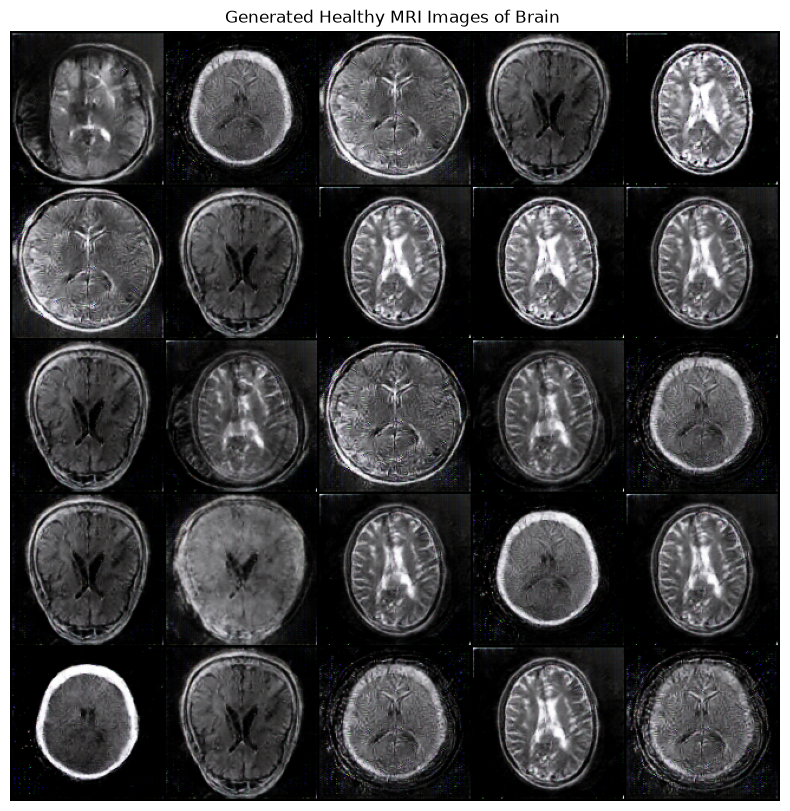

In [8]:
import torchvision
import matplotlib.pyplot as plt
Generator.eval()

with torch.no_grad():
    # Generate 25 random images
    noise = torch.randn(25, 100, 1, 1, device=device)
    fake_images = Generator(noise)

# Convert from [-1,1] to [0,1]
fake_images = (fake_images + 1) / 2

# Create a grid
grid = torchvision.utils.make_grid(fake_images.cpu(), nrow=5)

# Display
plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Generated Healthy MRI Images of Brain ")
plt.show()

In [9]:
import torch
import os

save_path = r"F:\Work\Python Learning" # Specify the path where you want to save the model
os.makedirs(save_path, exist_ok=True)

torch.save(Generator.state_dict(), os.path.join(save_path, "Healthy MRI of Brain.pth"))

print("Generator saved successfully!")

Generator saved successfully!


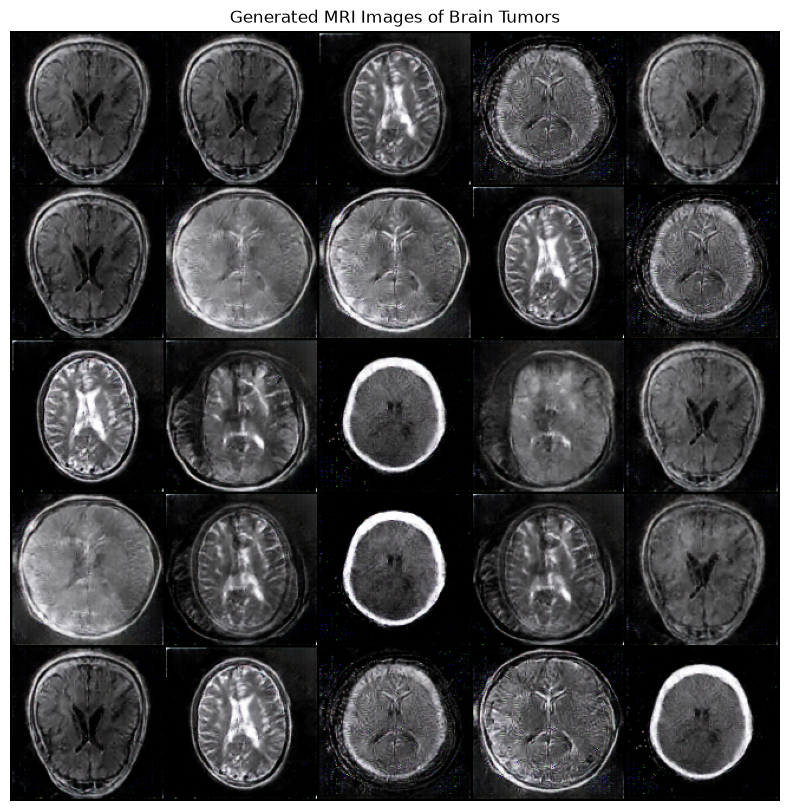

In [34]:
# Run This If you want to generate images from the trained Generator#
# Make sure that the path to the saved parameters is correct and the Generator class is defined in the same way as when it was saved.

import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# Generator
# ------------------------
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()

        self.layers = nn.Sequential(

            # Input: (100,1,1)
            nn.ConvTranspose2d(noise_dim, 1024, 4, 1, 0, bias=False),
            nn.BatchNorm2d(1024),
            nn.ReLU(True),

            # 4x4
            nn.ConvTranspose2d(1024, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            # 8x8
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # 16x16
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 32x32
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 64x64
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()

            # Output: (3,128,128)
        )

    def forward(self, x):
        return self.layers(x)

# ------------------------
# Load trained Generator
# ------------------------
Generator = Generator().to(device)

Generator.load_state_dict(
    torch.load(
        r"F:\Work\Python Learning\Healthy MRI of Brain.pth", # Specify the path to the saved model parameters
        map_location=device
    )
)

Generator.eval()

# ------------------------
# Generate Images
# ------------------------
with torch.no_grad():
    noise = torch.randn(25, 100, 1, 1, device=device)
    fake_images = Generator(noise)

# Convert from [-1,1] to [0,1]
fake_images = (fake_images + 1) / 2

grid = torchvision.utils.make_grid(fake_images.cpu(), nrow=5)

plt.figure(figsize=(10,10))
plt.imshow(grid.permute(1,2,0))
plt.axis("off")
plt.title("Generated MRI Images of Brain Tumors")
plt.show()